# SAM 3D Body × Sapiens2 — the two local Meta models on one photo

Both models are on this box and both run in the shared `.venv` (Python 3.11, torch 2.11.0+cu128,
RTX 4090, CUDA). This notebook runs them on the same image and puts their outputs together:

| model | what it gives | weights on disk |
| :--- | :--- | :--- |
| **SAM 3D Body** (dinov3, `pivot/sam-3d-body`) | 18,439-vert MHR body in metres, 45 identity coefficients, 204 MHR model params, 70 keypoints, camera translation | `pivot/sam-3d-body/sam-3d-body-dinov3/checkpoints/` (2.11 GB + 696 MB MHR TorchScript) |
| **Sapiens2** 0.4b pose (`pivot/sapiens2`) | **308** dense 2D keypoints — 70 body/hand + **238 face** points (glabella, nose, brows, lips, chin, iris, pupils) | `D:\AI_Models\...\Sapiens2\pose\sapiens2_0.4b_pose.safetensors` (1.70 GB) |

The join: 3DB's checkpoint carries a `keypoint_mapping` `(308, 18566)` linear map over its mesh
vertices + joints whose rows **70–307 are the same 238 face points** Sapiens2 predicts — the code
computes them and throws them away (`j3d = j3d[:, :70]`). One matmul recovers them on the MHR mesh,
so we can put 3DB's 3D face geometry and Sapiens2's 2D face landmarks in the same image.

**Two limits to read the numbers with** (both established in [`kb-sam-3d-body.md`](kb-sam-3d-body.md)):

1. 3DB **zeroes the 72 predicted expression coefficients** and body params 130–132 in its head
   (`mhr_head.py:316`, `:307`). Every 3DB mesh here has a **neutral jaw**, so mouth-region differences
   against Sapiens2 include expression mismatch — not just noise.
2. On a head-and-shoulders crop, 3DB's *body* is a prior (it extrapolates a whole body), so its body
   keypoints leave the frame. The notebook filters those out and says how many it dropped.

**Run it.**

*In JupyterLab* (kernel **`gnmvenv`**; launch from the repo root so this file is reachable):

```powershell
. .\scripts\env.ps1
$env:JUPYTER_PATH = "A:\dev\GNM-V\.cache\jupyter\share\jupyter"
$env:JUPYTER_RUNTIME_DIR = "$PWD\.cache\jupyter\runtime"
$env:JUPYTER_DATA_DIR = "$PWD\.cache\jupyter\data"
$env:JUPYTER_CONFIG_DIR = "$PWD\.cache\jupyter\config"
$env:IPYTHONDIR = "$PWD\.cache\ipython"
.\.venv\Scripts\jupyter-lab.exe --notebook-dir=. --port=8889 --ip=127.0.0.1 --no-browser
```

*Headless* (workspace-local runner; writes only beside this notebook):

```powershell
. .\scripts\env.ps1
$env:JUPYTER_PATH = "A:\dev\GNM-V\.cache\jupyter\share\jupyter"   # kernel "gnmvenv"
.\.venv\Scripts\python.exe pivot\sam3dbody-ingest\run_notebook.py
```

The executed copy lands in `exec/` and the images/JSON in `artifacts/`, both inside this folder.

No installs, no downloads, no venv: both models are read in place. ~40 s end to end (8–10 s of it is
the 3DB load, 4 s the Sapiens2 load). Artifacts (three JPEGs + `stats.json`) go to
`pivot/sam3dbody-ingest/artifacts/` unless `SAM3DBODY_NOTEBOOK_OUT` says otherwise; the executed
copy with its outputs is kept at `pivot/sam3dbody-ingest/exec/sam3d_sapiens2.ipynb`.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import cv2
import torch

# --- workspace ---------------------------------------------------------------------------------
REPO = Path(os.environ.get("GNM_REPO", r"A:\dev\GNM-V"))
assert (REPO / "AGENTS.md").is_file(), f"not the GNM-V repo: {REPO}"

THREEDB = REPO / "pivot" / "sam-3d-body"
THREEDB_CKPT = THREEDB / "sam-3d-body-dinov3" / "checkpoints" / "model.ckpt"
THREEDB_MHR = THREEDB / "sam-3d-body-dinov3" / "checkpoints" / "assets" / "mhr_model.pt"
SAPIENS_ROOT = REPO / "pivot" / "sapiens2"
SAPIENS_CKPT = Path(r"D:\AI_Models\3_Vision_Perception\Segmentation\facebook\Sapiens2\pose"
                    r"\sapiens2_0.4b_pose.safetensors")
SAPIENS_CFG = (SAPIENS_ROOT / "sapiens/pose/configs/keypoints308/shutterstock_goliath_3po"
               / "sapiens2_0.4b_keypoints308_shutterstock_goliath_3po-1024x768.py")

# artifacts land next to this notebook's evidence folder; override for read-only/sandboxed runs
OUTDIR = Path(os.environ.get("SAM3DBODY_NOTEBOOK_OUT",
                             str(REPO / "pivot" / "sam3dbody-ingest" / "artifacts")))
OUTDIR.mkdir(parents=True, exist_ok=True)

os.environ.setdefault("TORCH_HOME", str(REPO / ".cache" / "torch"))   # DINOv3 hub code (offline)
sys.path.insert(0, str(THREEDB))

for p in (THREEDB_CKPT, THREEDB_MHR, SAPIENS_CKPT, SAPIENS_CFG):
    print(f"{'ok ' if Path(p).exists() else 'MISSING'} {p}")

# --- test cases: two different jobs for the two models ------------------------------------------
#  full body (body pose actually visible)      head-and-shoulders (face is large, body is a prior)
CASES = [
    ("dancing",  "pivot/sam-3d-body/notebook/images/dancing.jpg",   [660, 210, 1510, 1430]),
    ("portrait", "pivot/teenage-woman-long-wavy-white-gray__01971-2947889296.png", [200, 60, 850, 1000]),
]

import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 9})
print("python", sys.version.split()[0], "| torch", torch.__version__,
      "| cuda", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

ok  A:\dev\GNM-V\pivot\sam-3d-body\sam-3d-body-dinov3\checkpoints\model.ckpt
ok  A:\dev\GNM-V\pivot\sam-3d-body\sam-3d-body-dinov3\checkpoints\assets\mhr_model.pt
ok  D:\AI_Models\3_Vision_Perception\Segmentation\facebook\Sapiens2\pose\sapiens2_0.4b_pose.safetensors
ok  A:\dev\GNM-V\pivot\sapiens2\sapiens\pose\configs\keypoints308\shutterstock_goliath_3po\sapiens2_0.4b_keypoints308_shutterstock_goliath_3po-1024x768.py
python 3.11.14 | torch 2.11.0+cu128 | cuda True NVIDIA GeForce RTX 4090


## 1 · SAM 3D Body — one image → an MHR body, identity and camera

The estimator is the manual-bbox path used by `pipeline/avatar/from_photo.py`: no ViTDet detector, no
SAM2 mask, no MoGe FOV model — you supply the person box. Input is a 1.25-padded 1:1 crop warped to
512²; with no intrinsics the camera gets a synthetic diagonal focal `f = sqrt(w²+h²)`.

The output is a dict per person. The fields that matter here: `pred_vertices (18439,3)` in metres
(root-centred, camera axes), `pred_keypoints_2d (70,2)` in **original image pixels** (no confidence
channel), `shape_params (45)`, `mhr_model_params (204)`, `pred_cam_t (3)`, `focal_length`, and
`expr_params (72)` — which is **all zeros by construction**.

In [2]:
t0 = time.time()
from sam_3d_body import SAM3DBodyEstimator, load_sam_3d_body

model3d, cfg3d = load_sam_3d_body(str(THREEDB_CKPT), device="cuda", mhr_path=str(THREEDB_MHR))
est = SAM3DBodyEstimator(model3d, cfg3d, human_detector=None,
                         human_segmentor=None, fov_estimator=None)
T_LOAD_3DB = time.time() - t0
print(f"\n3DB loaded in {T_LOAD_3DB:.2f} s  |  input {tuple(cfg3d.MODEL.IMAGE_SIZE)}  |  "
      f"faces {tuple(model3d.head_pose.faces.shape)}")
print("the 'state dict does not match exactly' warning is benign: 113 missing keys are TorchScript "
      "MHR buffers loaded separately + backbone.mask_token (0 unexpected keys).")

W1104 09:02:01.875000 59460 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
A:\dev\GNM-V\pivot\sam-3d-body\sam_3d_body\models\heads\mhr_head.py:33: UserWarning: Momentum is not enabled
  warnings.warn("Momentum is not enabled")


Loading SAM 3D Body model...


Using cache found in A:\dev\GNM-V\.cache\torch\hub\facebookresearch_dinov3_main
Ignored kwargs: {'drop_path': 0.1}
The model and loaded state dict do not match exactly

missing keys in source state_dict: backbone.encoder.mask_token, head_pose.hand_pose_comps_ori, head_pose.mhr.face_expressions_model.shape_vectors, head_pose.mhr.pose_correctives_model.pose_dirs_predictor.0.sparse_indices, head_pose.mhr.pose_correctives_model.pose_dirs_predictor.0.sparse_weight, head_pose.mhr.pose_correctives_model.pose_dirs_predictor.2.weight, head_pose.mhr.character_torch.skeleton.joint_translation_offsets, head_pose.mhr.character_torch.skeleton.joint_prerotations, head_pose.mhr.character_torch.skeleton.pmi, head_pose.mhr.character_torch.skeleton.joint_parents, head_pose.mhr.character_torch.mesh.rest_vertices, head_pose.mhr.character_torch.mesh.faces, head_pose.mhr.character_torch.mesh.texcoords, head_pose.mhr.character_torch.mesh.texcoord_faces, head_pose.mhr.character_torch.parameter_transform.parame

No human detector is used...
Mask-condition inference is not supported...
No FOV estimator... Using the default FOV!

3DB loaded in 11.85 s  |  input (512, 512)  |  faces (36874, 3)
the 'state dict does not match exactly' warning is benign: 113 missing keys are TorchScript MHR buffers loaded separately + backbone.mask_token (0 unexpected keys).


####### Please make sure the input image is in RGB format
case 'dancing'  2250x1500 px  |  inference 1.388 s (first call, cold)

-- output contract -----------------------------------------------------------------
  bbox                     (4,)               float32
  focal_length             ()                 float32
  pred_keypoints_3d        (70, 3)            float32
  pred_keypoints_2d        (70, 2)            float32
  pred_vertices            (18439, 3)         float32
  pred_cam_t               (3,)               float32
  pred_pose_raw            (266,)             float32
  global_rot               (3,)               float32
  body_pose_params         (133,)             float32
  hand_pose_params         (108,)             float32
  scale_params             (28,)              float32
  shape_params             (45,)              float32
  expr_params              (72,)              float32
  mask                     None
  pred_joint_coords        (127, 3)           float3

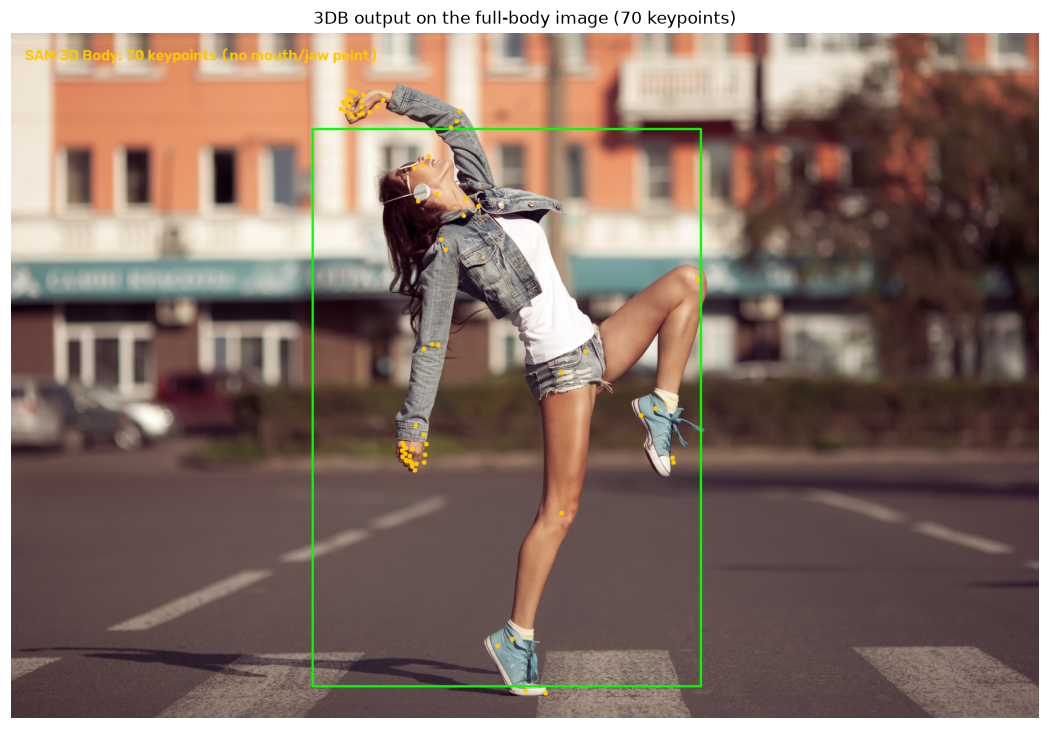

saved 01_3db_70_keypoints.jpg


In [3]:
def load_rgb(path):
    bgr = cv2.imread(str(REPO / path), cv2.IMREAD_COLOR)
    assert bgr is not None, f"cannot read {path}"
    return bgr, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def run_3db(rgb, bbox):
    t = time.time()
    out = est.process_one_image(rgb, bboxes=np.asarray([bbox], np.float32),
                                inference_type="body")[0]
    return out, time.time() - t

R3DB = {}
bgr0, rgb0 = load_rgb(CASES[0][1])
out0, dt = run_3db(rgb0, CASES[0][2])
R3DB[CASES[0][0]] = out0
print(f"case '{CASES[0][0]}'  {rgb0.shape[1]}x{rgb0.shape[0]} px  |  inference {dt:.3f} s (first call, cold)")

print("\n-- output contract -----------------------------------------------------------------")
for k, v in out0.items():
    if v is None:
        print(f"  {k:24s} None")
    else:
        a = np.asarray(v)
        print(f"  {k:24s} {str(a.shape):18s} {a.dtype}")
print(f"\n  |identity| (45) = {np.linalg.norm(out0['shape_params']):.3f}   "
      f"max|expr| (72) = {float(np.abs(out0['expr_params']).max()):.1f}   "
      f"focal = {float(out0['focal_length']):.1f} px   cam_t = {np.round(out0['pred_cam_t'], 3)} m")
print(f"  3DB's own 70 keypoints inside the image: "
      f"{100 * np.mean(((out0['pred_keypoints_2d'][:, 0] >= 0) & (out0['pred_keypoints_2d'][:, 0] < rgb0.shape[1]) & (out0['pred_keypoints_2d'][:, 1] >= 0) & (out0['pred_keypoints_2d'][:, 1] < rgb0.shape[0]))):.0f}%")

# --- overlay: 3DB's 70 keypoints + the person box
vis = bgr0.copy()
x1, y1, x2, y2 = [int(v) for v in CASES[0][2]]
cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
for x, y in out0["pred_keypoints_2d"]:
    if np.isfinite([x, y]).all():
        cv2.circle(vis, (int(round(x)), int(round(y))), 5, (0, 200, 255), -1)
cv2.putText(vis, "SAM 3D Body: 70 keypoints (no mouth/jaw point)", (30, 60),
            cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 200, 255), 3, cv2.LINE_AA)
p = OUTDIR / "01_3db_70_keypoints.jpg"
cv2.imwrite(str(p), vis)
plt.figure(figsize=(10, 6.7)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("3DB output on the full-body image (70 keypoints)"); plt.tight_layout(); plt.show()
print("saved", p.name)

## 2 · Sapiens2 — 308 dense keypoints, 238 of them on the face

Sapiens2's 0.4b pose head predicts the **308-keypoint** Sapiens format: indices **0–69** are the
body/foot/hand set (same names and order as 3DB's `mhr70`: nose, 2 eyes, 2 ears, shoulders, …, 42
hand points), and **70–307** are **238 dense face points** — glabella, nose bridge, brows, lids, iris,
pupil, 31 lip points, mouth corners, chin, ears. The 36 `teeth_*` points are not in the released set.

Two facts worth checking in the cell below: the mouth corners are **188/189** (outer) and **204/205**
(inner), the chin is **77** — and **there is no “jaw” keypoint anywhere** in the 308, so neither model
has a jaw landmark to give us.

In [4]:
t0 = time.time()
import types
sys.path.insert(0, str(SAPIENS_ROOT))
if "sapiens" not in sys.modules:            # bypass the eager package __init__ (it wants iopath)
    pkg = types.ModuleType("sapiens")
    pkg.__path__ = [str(SAPIENS_ROOT / "sapiens")]
    pkg.__version__ = "2.0.0"
    sys.modules["sapiens"] = pkg
import sapiens.backbones                                             # noqa: F401  (registers backbones)
from sapiens.pose.datasets import UDPHeatmap, parse_pose_metainfo
from sapiens.pose.models import init_model

sap = init_model(str(SAPIENS_CFG), str(SAPIENS_CKPT), device="cuda")
sap.pose_metainfo = parse_pose_metainfo(
    dict(from_file=str(SAPIENS_ROOT / "sapiens/pose/configs/_base_/keypoints308.py")))
_cfg = dict(sap.cfg.codec); _cfg.pop("type")
sap.codec = UDPHeatmap(**_cfg)
KP_NAMES = [sap.pose_metainfo["keypoint_id2name"][i] for i in range(sap.pose_metainfo["num_keypoints"])]
T_LOAD_SAP = time.time() - t0

assert len(KP_NAMES) == 308, len(KP_NAMES)
print(f"\nSapiens2 loaded in {T_LOAD_SAP:.2f} s  |  {len(KP_NAMES)} keypoints")
print("  head rows 0-4:", [f"{i}={n}" for i, n in enumerate(KP_NAMES[:5])])
print("  face rows 70+ :", KP_NAMES[70:74], "...", "| n_face =", len(KP_NAMES) - 70)
MOUTH_OUT = [i for i, n in enumerate(KP_NAMES) if "outer_corner_of_mouth" in n]
MOUTH_IN  = [i for i, n in enumerate(KP_NAMES) if "inner_corner_of_mouth" in n]
CHIN_IDX  = [i for i, n in enumerate(KP_NAMES) if n == "tip_of_chin"]
print("  mouth corners:", MOUTH_OUT, [KP_NAMES[i] for i in MOUTH_OUT],
      "| inner:", MOUTH_IN, "| chin:", CHIN_IDX)
print("  names containing 'jaw':", [n for n in KP_NAMES if "jaw" in n.lower()] or "NONE",
      "| containing 'teeth':", sum("teeth" in n for n in KP_NAMES))

Model loaded from D:\AI_Models\3_Vision_Perception\Segmentation\facebook\Sapiens2\pose\sapiens2_0.4b_pose.safetensors

Sapiens2 loaded in 3.83 s  |  308 keypoints
  head rows 0-4: ['0=nose', '1=left_eye', '2=right_eye', '3=left_ear', '4=right_ear']
  face rows 70+ : ['center_of_glabella', 'center_of_nose_root', 'tip_of_nose_bridge', 'midpoint_1_of_nose_bridge'] ... | n_face = 238
  mouth corners: [188, 189] ['r_outer_corner_of_mouth', 'l_outer_corner_of_mouth'] | inner: [204, 205] | chin: [77]
  names containing 'jaw': NONE | containing 'teeth': 0


case 'dancing': Sapiens2 308 keypoints in 0.555 s  |  score median 0.918 (face p10 0.780)


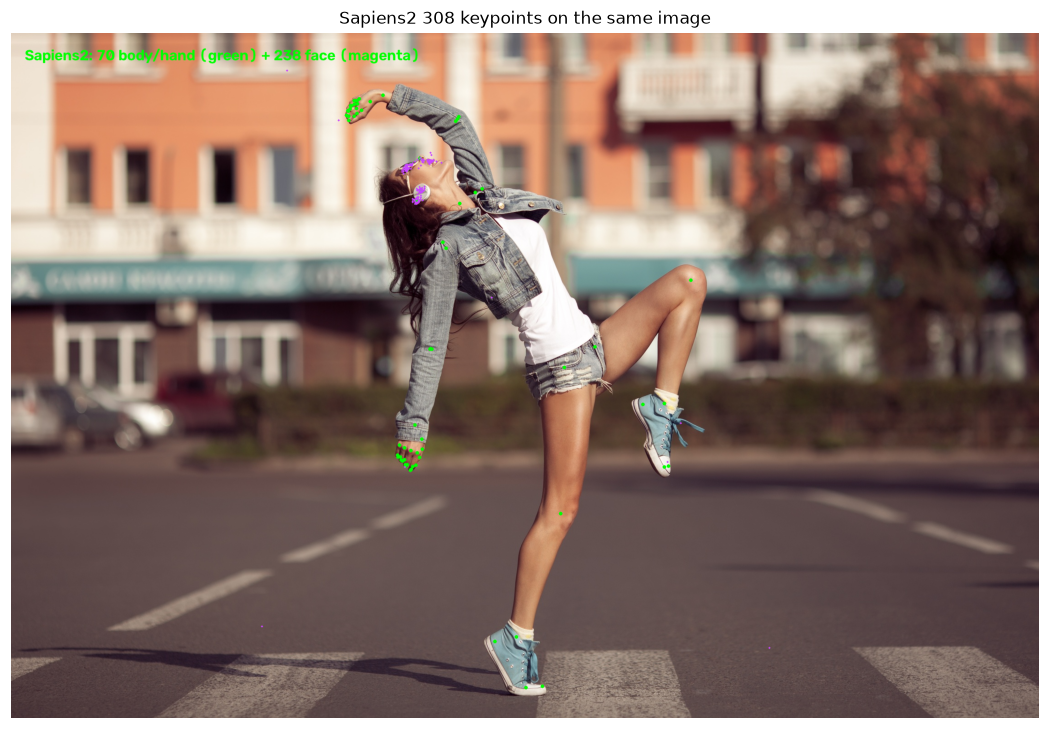

saved 02_sapiens2_308_keypoints.jpg


In [5]:
def run_sapiens(bgr, bbox):
    # 308 2D keypoints in ORIGINAL image pixels + per-point score (0..1)
    info = dict(img=bgr, bbox=np.asarray([bbox], np.float32), bbox_score=np.ones(1, np.float32))
    data = sap.pipeline(info)
    data = sap.data_preprocessor(data)
    with torch.no_grad():
        pred = sap(data["inputs"])
    kp, score = sap.codec.decode(pred[0].cpu().numpy())
    kp = kp[0] if np.ndim(kp) == 3 else kp
    score = np.asarray(score[0] if np.ndim(score) == 2 else score).reshape(-1)
    meta = data["data_samples"]["meta"]                      # undo the crop -> original pixels
    isz = np.asarray(meta["input_size"]).reshape(-1).astype(np.float64)
    bc = np.asarray(meta["bbox_center"]).reshape(-1).astype(np.float64)
    bs = np.asarray(meta["bbox_scale"]).reshape(-1).astype(np.float64)
    return kp / isz[None, :] * bs[None, :] + bc[None, :] - 0.5 * bs[None, :], score

SAP = {}
t = time.time(); kp_sap0, sc_sap0 = run_sapiens(bgr0, CASES[0][2]); dt_s = time.time() - t
SAP[CASES[0][0]] = (kp_sap0, sc_sap0)
print(f"case '{CASES[0][0]}': Sapiens2 {len(kp_sap0)} keypoints in {dt_s:.3f} s  |  "
      f"score median {np.median(sc_sap0):.3f} (face p10 {np.percentile(sc_sap0[70:], 10):.3f})")

vis = bgr0.copy()
for i in range(70):
    cv2.circle(vis, tuple(np.round(kp_sap0[i]).astype(int)), 4, (0, 255, 0), -1)
for i in range(70, 308):
    cv2.circle(vis, tuple(np.round(kp_sap0[i]).astype(int)), 2, (255, 70, 200), -1)
cv2.putText(vis, "Sapiens2: 70 body/hand (green) + 238 face (magenta)", (30, 60),
            cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 255, 0), 3, cv2.LINE_AA)
p = OUTDIR / "02_sapiens2_308_keypoints.jpg"
cv2.imwrite(str(p), vis)
plt.figure(figsize=(10, 6.7)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Sapiens2 308 keypoints on the same image"); plt.tight_layout(); plt.show()
print("saved", p.name)

## 3 · The join — 3DB's discarded 238 face landmarks meet Sapiens2's 238

`head_pose.keypoint_mapping` is a fixed `(308, 18566)` matrix: each row is a set of weights over the
18,439 MHR vertices + 127 joints. Every row sums to exactly 1 and the weights are a blend of a handful
of vertices (mean 8.7; the smallest entry in the whole matrix is −7e−14, float noise). 3DB applies it
every inference and then keeps `[:, :70]`; rows **70–307** are the dense face block. To place them in
the *image*:

1. run the local MHR TorchScript with the returned `(identity 45, model_params 204)` and zero
   expression → native-frame vertices/joints (cm, y-up);
2. `mapping @ [verts; joints]` → 308 3D points in cm, same frame;
3. `/100`, invert 3DB's y/z flip, add `pred_cam_t`, project with 3DB's focal and principal point.

**Self-check that this is the right path:** rows 0–69 must reproduce the `pred_keypoints_2d` that 3DB
ships (`< 0.01 px` expected — the model itself does exactly this matmul).

In [6]:
sd = torch.load(str(THREEDB_CKPT), map_location="cpu", weights_only=True, mmap=True)
KEY = next(k for k in sd if k.endswith("head_pose.keypoint_mapping"))
KMAP = sd[KEY].detach().float().cpu().numpy().astype(np.float64)
print(f"{KEY}  {KMAP.shape}  row sums {KMAP.sum(1).min():.6f}..{KMAP.sum(1).max():.6f}  "
      f"min entry {KMAP.min():.1e}  nonzero/row {KMAP.astype(bool).sum(1).min()}..{KMAP.astype(bool).sum(1).max()}  "
      f"rows mixing in joints {int((KMAP[:, 18439:] != 0).any(1).sum())}")

def kp308_metres(out):
    # all 308 keypoints, in 3DB output frame (metres, root-centred, camera axes)
    beta = torch.from_numpy(np.asarray(out["shape_params"], np.float32))[None].cuda()
    params = torch.from_numpy(np.asarray(out["mhr_model_params"], np.float32))[None].cuda()
    expr = torch.zeros(1, 72, dtype=torch.float32, device="cuda")          # 3DB always zeroes this
    verts_cm, skel = model3d.head_pose.mhr(beta, params, expr)            # native MHR TorchScript
    vj = np.concatenate([verts_cm[0].float().cpu().numpy(),
                         skel[0, :, :3].float().cpu().numpy()], axis=0)   # (18566, 3) cm
    kp_cm = KMAP @ vj
    kp_m = kp_cm / 100.0
    kp_m[:, [1, 2]] *= -1                                                 # 3DB's camera convention
    return kp_m

def project(kp_m, out, width, height):
    # 3DB projection: p_cam = p + cam_t; x = f*X/Z + cx, y = f*Y/Z + cy
    f = float(out["focal_length"]); t = np.asarray(out["pred_cam_t"], np.float64)
    pc = kp_m + t[None, :]
    ok = pc[:, 2] > 1e-6
    uv = np.full((len(kp_m), 2), np.nan)
    uv[ok, 0] = f * pc[ok, 0] / pc[ok, 2] + width / 2.0
    uv[ok, 1] = f * pc[ok, 1] / pc[ok, 2] + height / 2.0
    return uv

kp3_m = kp308_metres(out0)
kp3_uv = project(kp3_m, out0, rgb0.shape[1], rgb0.shape[0])
own = np.asarray(out0["pred_keypoints_2d"], np.float64)
err = np.linalg.norm(kp3_uv[:70] - own, axis=1)
print(f"\nself-check: projected rows 0-69 vs 3DB's own pred_keypoints_2d  ->  max {err.max():.5f} px, "
      f"median {np.median(err):.5f} px   {'OK' if err.max() < 0.01 else 'MISMATCH'}")
print("3D landmark examples (metres, 3DB frame) — neutral jaw, because expr=0:")
for i, nm in [(0, "nose"), (MOUTH_OUT[0], KP_NAMES[MOUTH_OUT[0]]), (MOUTH_OUT[1], KP_NAMES[MOUTH_OUT[1]]),
              (MOUTH_IN[0], KP_NAMES[MOUTH_IN[0]]), (CHIN_IDX[0], KP_NAMES[CHIN_IDX[0]])]:
    print(f"  {i:3d} {nm:28s} {np.round(kp3_m[i], 4)}")

head_pose.keypoint_mapping  (308, 18566)  row sums 1.000000..1.000000  min entry -6.8e-14  nonzero/row 1..43  rows mixing in joints 49

self-check: projected rows 0-69 vs 3DB's own pred_keypoints_2d  ->  max 0.00012 px, median 0.00005 px   OK
3D landmark examples (metres, 3DB frame) — neutral jaw, because expr=0:
    0 nose                         [-0.4325 -1.539  -0.0865]
  188 r_outer_corner_of_mouth      [-0.4067 -1.4989 -0.1112]
  189 l_outer_corner_of_mouth      [-0.3898 -1.5138 -0.0642]
  204 r_inner_corner_of_mouth      [-0.4071 -1.5002 -0.1093]
   77 tip_of_chin                  [-0.3607 -1.5065 -0.0994]


## 4 · How well do the two models agree?

Independent outputs: 3DB's 3D landmarks projected through its own camera vs Sapiens2's 2D detections.
They are different modalities (mesh identity + body prior vs image heatmaps), so agreement is a
sanity check, not a quality metric. Points are excluded when either model puts them outside the image
(3DB's body leaves a head-crop frame — that is the prior showing, not an error). The `iris+pupil`
rows are kept separate on purpose: the MHR mesh has **no eyeball geometry**, so those rows are a
surface extrapolation, and on the small dancing face Sapiens2's own iris/pupil detections are noisy —
that pair dominates the outliers below.

In [7]:
import pandas as pd

GROUPS = [("head (0-4)", range(0, 5)), ("body (5-20)", range(5, 21)),
          ("hands (21-69)", range(21, 70)), ("face (70-307)", range(70, 308)),
          ("face w/o iris+pupil (70-271)", range(70, 272)),
          ("iris+pupil (272-307)", range(272, 308)),
          ("mouth outer (188/189)", MOUTH_OUT), ("mouth inner (204/205)", MOUTH_IN),
          ("chin (77)", CHIN_IDX)]
ROWS, STATS = [], {}
for name, path, bbox in CASES:
    bgr, rgb = load_rgb(path); H, W = rgb.shape[:2]
    if name not in R3DB:
        R3DB[name], t3 = run_3db(rgb, bbox)
    if name not in SAP:
        SAP[name] = run_sapiens(bgr, bbox)
    out, (kp_sap, sc_sap) = R3DB[name], SAP[name]
    kp3 = project(kp308_metres(out), out, W, H)
    both_in = ((kp3[:, 0] >= 0) & (kp3[:, 0] < W) & (kp3[:, 1] >= 0) & (kp3[:, 1] < H)
               & np.isfinite(kp3).all(1))
    e = np.linalg.norm(kp3 - kp_sap, axis=1)
    dropped = int((~both_in).sum())
    STATS[name] = {"W": W, "H": H, "dropped": dropped,
                   "own_70_in_frame_pct": float(100 * np.mean(both_in[0:70]))}
    for label, idx in GROUPS:
        idx = np.asarray(list(idx))
        sel = idx[both_in[idx]]
        ee = e[sel]
        ROWS.append({"case": name, "group": label, "n_used": len(ee), "n_dropped": len(idx) - len(ee),
                     "median_px": float(np.median(ee)) if len(ee) else np.nan,
                     "p90_px": float(np.percentile(ee, 90)) if len(ee) else np.nan,
                     "rms_px": float(np.sqrt(np.mean(ee ** 2))) if len(ee) else np.nan})
R = pd.DataFrame(ROWS)
print("Agreement 3DB-projected 308 vs Sapiens2 308 (original-image pixels):")
display(R.pivot_table(index="group", columns="case", values=["median_px", "p90_px"], aggfunc="first")
        .round(1))
print("points used / dropped per group (dropped = a model put the point outside the image):")
display(R.pivot_table(index="group", columns="case", values=["n_used", "n_dropped"], aggfunc="first")
        .astype("Int64"))
print("\npoints the two models disagree on most (top 8 by px):")
for name in STATS:
    out, (kp_sap, _) = R3DB[name], SAP[name]
    kp3 = project(kp308_metres(out), out, STATS[name]["W"], STATS[name]["H"])
    e = np.linalg.norm(kp3 - kp_sap, axis=1)
    e[~np.isfinite(kp3).all(1)] = np.nan
    worst = np.argsort(np.where(np.isnan(e), -1, e))[::-1][:8]
    print(f"  {name:9s}", [(int(i), KP_NAMES[i][:22], int(round(e[i]))) for i in worst])
print("\nwhy the portrait drops body points: 3DB's own 70 keypoints in frame =",
      {k: f"{v['own_70_in_frame_pct']:.0f}%" for k, v in STATS.items()},
      "-> on a head-and-shoulders crop the body/hands are a prior, so those keypoints leave the frame")
print("and are excluded; only the face/head rows are comparable there. The full-body image keeps all 308 in frame.")
_ = (OUTDIR / "stats.json").write_text(json.dumps({"stats": STATS, "rows": ROWS}, indent=2))

####### Please make sure the input image is in RGB format
Agreement 3DB-projected 308 vs Sapiens2 308 (original-image pixels):


median_px           p90_px         
case                           dancing portrait dancing portrait
group                                                           
body (5-20)                       13.8      NaN    23.9      NaN
chin (77)                         24.2      5.3    24.2      5.3
face (70-307)                     19.0     18.1    39.1     51.3
face w/o iris+pupil (70-271)      18.7     17.2    31.7     46.4
hands (21-69)                     13.0     31.3    20.5     31.3
head (0-4)                        18.9     16.2    31.6     46.8
iris+pupil (272-307)              24.7     29.2   732.5    281.5
mouth inner (204/205)             21.0     12.4    23.7     12.6
mouth outer (188/189)             21.7     13.7    24.6     14.2

points used / dropped per group (dropped = a model put the point outside the image):


n_dropped           n_used         
case                           dancing portrait dancing portrait
group                                                           
body (5-20)                          0       16      16        0
chin (77)                            0        0       1        1
face (70-307)                        0        0     238      238
face w/o iris+pupil (70-271)         0        0     202      202
hands (21-69)                        0       48      49        1
head (0-4)                           0        0       5        5
iris+pupil (272-307)                 0        0      36       36
mouth inner (204/205)                0        0       2        2
mouth outer (188/189)                0        0       2        2


points the two models disagree on most (top 8 by px):
  dancing   [(299, 'r_center_of_pupil', 1309), (307, 'r_border_of_pupil_midp', 1058), (295, 'l_border_of_pupil_9', 846), (290, 'l_center_of_pupil', 801), (298, 'l_border_of_pupil_midp', 663), (293, 'l_border_of_pupil_12', 358), (304, 'r_border_of_pupil_9', 333), (294, 'l_border_of_pupil_midp', 205)]
  portrait  [(18, 'right_big_toe', 5025), (19, 'right_small_toe', 4591), (15, 'left_big_toe', 4516), (16, 'left_small_toe', 4005), (20, 'right_heel', 3551), (14, 'right_ankle', 3546), (13, 'left_ankle', 3387), (17, 'left_heel', 3269)]

why the portrait drops body points: 3DB's own 70 keypoints in frame = {'dancing': '100%', 'portrait': '9%'} -> on a head-and-shoulders crop the body/hands are a prior, so those keypoints leave the frame
and are excluded; only the face/head rows are comparable there. The full-body image keeps all 308 in frame.


In [ ]:
# face close-up on the portrait: Sapiens2 (magenta) vs 3DB's recovered face landmarks (cyan)
name, path, bbox = CASES[1]
bgr, rgb = load_rgb(path); H, W = rgb.shape[:2]
out, (kp_sap, sc_sap) = R3DB[name], SAP[name]
kp3 = project(kp308_metres(out), out, W, H)

face = kp_sap[70:308]
fx1, fy1 = np.floor(face.min(0)).astype(int); fx2, fy2 = np.ceil(face.max(0)).astype(int)
pad = int(0.25 * max(fx2 - fx1, fy2 - fy1))
fx1, fy1 = max(fx1 - pad, 0), max(fy1 - pad, 0); fx2, fy2 = min(fx2 + pad, W), min(fy2 + pad, H)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, zoom in zip(axes, (False, True)):
    img = bgr.copy()
    for i in range(70, 308):
        if np.isfinite(kp3[i]).all():
            cv2.drawMarker(img, tuple(np.round(kp3[i]).astype(int)), (255, 230, 0),
                           cv2.MARKER_CROSS, 7, 1)                                  # cyan crosses = 3DB
    for i in range(70, 308):
        cv2.circle(img, tuple(np.round(kp_sap[i]).astype(int)), 2, (200, 70, 255), -1)  # magenta = Sapiens2
    for i in MOUTH_OUT + MOUTH_IN + CHIN_IDX:
        p = kp_sap[i]
        cv2.circle(img, tuple(np.round(p).astype(int)), 11, (0, 0, 255), 2)
        cv2.putText(img, f"{i}", tuple(np.round(p).astype(int) + np.array([12, -8])),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2, cv2.LINE_AA)
    crop = img[fy1:fy2, fx1:fx2] if zoom else img
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title("face close-up" if zoom else "portrait"); ax.axis("off")
fig.text(0.01, 0.015, "cyan + = 3DB's 238 recovered mesh landmarks    magenta dot = Sapiens2's 238 face keypoints"
         "    red ring = mouth corners 188/189, 204/205 and chin 77", fontsize=9)
plt.suptitle("Same 238 face points, two Meta models: mesh identity (3DB) vs image heatmaps (Sapiens2)",
             fontsize=10)
plt.tight_layout(rect=(0, 0.035, 1, 0.97))
p = OUTDIR / "03_face_238_3db_vs_sapiens2.jpg"
plt.savefig(p, bbox_inches="tight"); plt.show()
print("saved", p.name)
print("mouth corner 2D: Sapiens2", np.round(kp_sap[MOUTH_OUT], 1), "| 3DB projected", np.round(kp3[MOUTH_OUT], 1))

## 5 · What the mouth rows actually say (and why the jaw is absent)

- Rows **188/189** are the outer mouth corners, **204/205** the inner corners, **77** the chin tip,
  **190–219** the lip set, **272–289** the iris, **290–307** the pupil. They are real landmarks on the
  MHR *surface* — the mesh has no teeth, tongue or eyeballs, so the iris/pupil rows are extrapolated
  onto the face surface and should be treated as approximate; the lip/chin rows sit on actual skin.
- They are computed from the mesh, so they move only with what the mesh moves with: identity, pose,
  and expression. `expr_params` is zero by construction, and this notebook also confirms it
  numerically. **Mouth-opening in the photo cannot show up here**, which is why the mouth rows are the
  ones where the two models disagree most (Sapiens2 sees the expression, 3DB has none).
- The 70 *released* keypoints have no mouth or jaw point (only nose/eyes/ears among the head rows).
  The 238 face rows close that gap for geometry points, but there is still **no jaw DOF**: 3DB's head
  also zeroes body params 130–132, and the MHR `jawDrop` blendshape is a separate 72-vector the model
  never fills. Anything that talks has to drive that from outside — see `kb-sam-3d-body.md` §4–§5.

In [8]:
out = R3DB["portrait"]
print("numerical evidence for the neutral jaw:")
print(f"  max|expr_params| = {float(np.abs(out['expr_params']).max()):.1f}   (72 values, all zero)")
print(f"  the 70 released keypoints: {', '.join(KP_NAMES[:5])} — no mouth, no jaw")
print(f"  mouth names in the 308 exist only at indices {MOUTH_OUT + MOUTH_IN} (face block, recovered here)")
print(f"  'jaw' in the 80 Sapiens names: {[n for n in KP_NAMES if 'jaw' in n.lower()] or 'none'}")

for name in R3DB:
    out = R3DB[name]
    kp_sap, sc = SAP[name]
    kp3 = project(kp308_metres(out), out, STATS[name]["W"], STATS[name]["H"])
    ok = np.isfinite(kp3).all(1)
    mouth = np.concatenate([MOUTH_OUT, MOUTH_IN])
    d = np.linalg.norm(kp3[mouth] - kp_sap[mouth], axis=1)
    print(f"  {name:9s} mouth-corner disagreement {np.round(d, 1)} px   "
          f"(Sapiens2 face score {np.median(sc[70:]):.2f}) -> expression mismatch, not geometry")

numerical evidence for the neutral jaw:
  max|expr_params| = 0.0   (72 values, all zero)
  the 70 released keypoints: nose, left_eye, right_eye, left_ear, right_ear — no mouth, no jaw
  mouth names in the 308 exist only at indices [188, 189, 204, 205] (face block, recovered here)
  'jaw' in the 80 Sapiens names: none
  dancing   mouth-corner disagreement [18.2 25.3 17.5 24.4] px   (Sapiens2 face score 0.90) -> expression mismatch, not geometry
  portrait  mouth-corner disagreement [14.3 13.2 12.6 12.2] px   (Sapiens2 face score 0.91) -> expression mismatch, not geometry


## 6 · What this notebook establishes, and what it does not

**Establishes (measured, reproducible here):**
- Both Meta models run in the shared `.venv` on the 4090: 3DB load ~8–10 s, ~0.2 s/image (`body`);
  Sapiens2 load ~4 s, ~0.3 s/image for 308 keypoints.
- 3DB's `keypoint_mapping` rows 70–307 reconstruct **238 dense face landmarks** on the returned MHR
  mesh, and the projection is self-consistent (rows 0–69 reproduce 3DB's own 2D keypoints).
- Sapiens2's 238 face keypoints and 3DB's 238 mesh landmarks can be placed in the same image pixels,
  so they can be compared/used for camera fitting (this is what `pipeline/avatar/panel_landmarks.py`
  does for the texture pass).
- On a full-body photo the two models' 308 keypoints agree to ~13–24 px median; on a head crop the
  face block agrees to ~18 px while **body/hand keypoints are a prior** (3DB's own 70 are 9 % in frame).

**Does not:**
- produce facial expression or jaw motion — 3DB zeroes the 72 expression coefficients *and* body
  params 130–132 (`mhr_head.py:316, :307`); every mesh here is neutral-jaw;
- give teeth, tongue or eyeballs — one watertight MHR surface, no part geometry;
- transfer the landmarks to GNM's 17,821-vertex head — MHR topology only, needs a correspondence;
- validate its inputs: a bad bbox silently yields NaN or plausible garbage (`kb-sam-3d-body.md` §3).

**Next for the voice coupling** is not this notebook: it is driving MHR's 72 `blend_45..116` (and the
3–4 jaw params) from our own articulation model and measuring formants — that is the A-track
experiment. This notebook is the hand-off point: 3DB gives identity + camera + surface landmarks,
Sapiens2 gives dense 2D, and both are clean to call.

In [9]:
print("artifacts in", OUTDIR)
total = 0
for p in sorted(OUTDIR.iterdir()):
    if p.is_file():
        total += p.stat().st_size
        print(f"  {p.stat().st_size/1024:8.1f} KB  {p.name}")
print(f"  total {total/1024:.1f} KB")
print("\nruntime: 3DB load %.1f s | Sapiens2 load %.1f s | 2 pages x 2 models" % (T_LOAD_3DB, T_LOAD_SAP))

artifacts in A:\dev\GNM-V\pivot\sam3dbody-ingest\artifacts
     661.2 KB  01_3db_70_keypoints.jpg
     653.3 KB  02_sapiens2_308_keypoints.jpg
      96.9 KB  03_face_238_3db_vs_sapiens2.jpg
       4.3 KB  stats.json
  total 1415.8 KB

runtime: 3DB load 12.2 s | Sapiens2 load 3.8 s | 2 pages x 2 models
